In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Đọc dữ liệu từ file đã xử lý ở các stage trước


In [3]:
df = pd.read_csv('NguyenTheHoang_final_eda.csv')

C:\Users\CHAU TINH TIEN\AppData\Local\Temp\ipykernel_16836\846591219.py:1: DtypeWarning: Columns (0: Transaction ID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('NguyenTheHoang_final_eda.csv')


# 2. Tạo nhãn Target (Ví dụ: Giao dịch giá trị cao dựa trên phân vị 75% của Sales Amount)
# Hoặc nếu đã có cột 'Price Range', có thể map trực tiếp

In [15]:
threshold = df['Sales Amount'].quantile(0.75)
df['High_Value'] = (df['Sales Amount'] > threshold).astype(int)

# Chọn các biến đặc trưng (Features) và nhãn (Target)
# Loại bỏ các cột không cần thiết hoặc trùng lặp với target

In [17]:
features = ['Quantity', 'Price', 'Store Location', 'Source', 'Month', 'Weekday', 'Product Name']
X = df[features].copy()
y = df['High_Value'].astype(int)
numeric_features = ['Quantity', 'Price', 'Month']
categorical_features = ['Store Location', 'Source', 'Weekday', 'Product Name']
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

for col in categorical_features:
    X[col] = X[col].astype(str)

print(f"Số lượng biến số: {len(numeric_features)}")
print(f"Số lượng biến phân loại: {len(categorical_features)}")

Số lượng biến số: 3
Số lượng biến phân loại: 4


# 3. Chia tập train/test (80/20)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Xây dựng Pipeline tiền xử lý

In [19]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 5. Khởi tạo 2 mô hình (có dùng class_weight='balanced' để xử lý mất cân bằng lớp nếu có)

In [20]:
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Decision Tree': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
    ])
}

# 6. Huấn luyện và Đánh giá mô hình


--- Đang huấn luyện: Logistic Regression ---
Accuracy: 0.9996

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25396
           1       1.00      1.00      1.00      6336

    accuracy                           1.00     31732
   macro avg       1.00      1.00      1.00     31732
weighted avg       1.00      1.00      1.00     31732



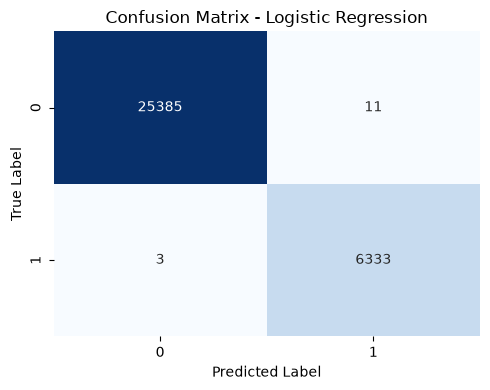


--- Đang huấn luyện: Decision Tree ---
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25396
           1       1.00      1.00      1.00      6336

    accuracy                           1.00     31732
   macro avg       1.00      1.00      1.00     31732
weighted avg       1.00      1.00      1.00     31732



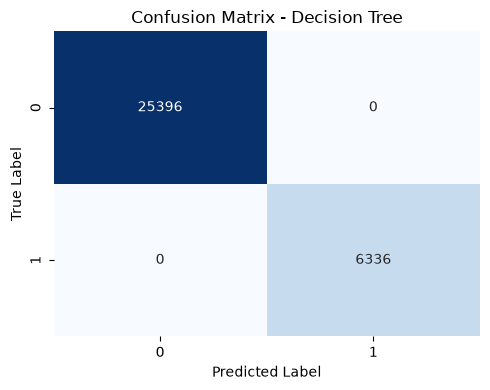

In [ ]:
best_model = None
best_accuracy = 0
best_model_name = ""

for name, model in models.items():
    print(f"\n--- Đang huấn luyện: {name} ---")
    model.fit(X_train, y_train)  #
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
   
    plt.figure(figsize=(5, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{name.lower().replace(" ", "_")}.png')
    plt.show()
    
    
    if acc > best_accuracy:
        best_accuracy = acc
        best_model = model
        best_model_name = name

# 8. Xuất mô hình tốt nhất ra file .pkl

In [23]:
model_filename = 'models/PhamVietTien_classfication_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_model, file)